# Figure 1a
Cell population dynamics -/+ erlotinib on different stiffnesses

#### Load libraries
Should use ECM_model conda environment (see README)

In [1]:
import matplotlib.pyplot as plt
from matplotlib import rc, rcParams
import numpy as np
import os
import glob
from scipy.signal import savgol_filter
from scipy.stats import exponnorm
import pandas as pd
import math
from pathlib import Path
import re
import sys

#### Set global parameters
`SAVEFILES` = logical whether to write files to disk  
`OVERWRITE` = logical whether to overwrite files if already exists  
`SAVEDIR` = Path (outside of git repo) to save output files  
`DATADIR` = Path to data files  


In [2]:
SAVEFILES = True
OVERWRITE = True

SAVEDIR = Path(os.path.expanduser("~/ECM_mod_output"))
if not os.path.exists(SAVEDIR) and SAVEFILES:
    os.mkdir(SAVEDIR)
    
DATADIR = "../../Data/Exp_Cell_Counts"

rcParams.update({'figure.autolayout': True})

# add path to fit functions
sys.path.insert(0, "./../../Python")
from fits import emg_fit_func, fit_EMGMM


#### Load cell population data

In [3]:
filepaths = os.listdir(DATADIR)
filenames = [f for f in filepaths if re.match(r'^DIP_DS8', f)]
filepaths = [Path(DATADIR, f) for f in filenames]
filepaths.sort()
filepaths

[WindowsPath('../../Data/Exp_Cell_Counts/DIP_DS8_0p2kPa_DMSO.txt'),
 WindowsPath('../../Data/Exp_Cell_Counts/DIP_DS8_0p2kPa_ERL.txt'),
 WindowsPath('../../Data/Exp_Cell_Counts/DIP_DS8_4kPa_DMSO.txt'),
 WindowsPath('../../Data/Exp_Cell_Counts/DIP_DS8_4kPa_ERL.txt'),
 WindowsPath('../../Data/Exp_Cell_Counts/DIP_DS8_55kPa_DMSO.txt'),
 WindowsPath('../../Data/Exp_Cell_Counts/DIP_DS8_55kPa_ERL.txt')]

In [4]:
all_response = []
for f in filepaths:
    all_response.append(np.loadtxt(f,delimiter=','))

means=[]
for vals in range(len(all_response)):
    means.append(np.mean(all_response[vals],axis=1))
    
stdevs=[]
for vals in range(len(all_response)):
    stdevs.append(np.std(all_response[vals],axis=1))

t = np.arange(0,420/3,1/3)
t1 = np.arange(0,363/3,1/3)


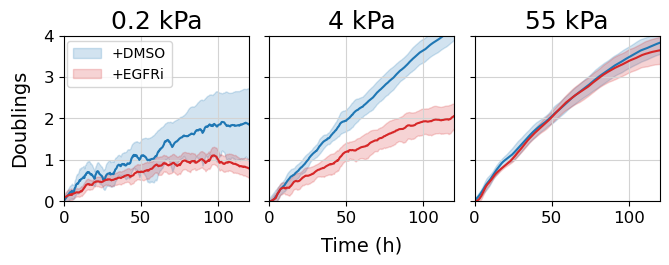

In [5]:
win = 21
pol = 2
size = (7,3)
c1 = "tab:blue"
c2 = "tab:red"
xmin = 0
xmax = 120
ymin = 0
ymax = 4

params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 14,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

fig, axes = plt.subplots(1, 3, figsize=size)

axes[0].plot(t, savgol_filter(means[0],win,pol), color=c1)
axes[0].fill_between(t, savgol_filter(means[0] - stdevs[0],win,pol),
                     savgol_filter(means[0] + stdevs[0],win,pol), color=c1, alpha=0.2, label='+DMSO')
axes[0].plot(t, savgol_filter(means[1],win,pol), color=c2)
axes[0].fill_between(t, savgol_filter(means[1] - stdevs[1],win,pol),
                     savgol_filter(means[1] + stdevs[1],win,pol), color=c2, alpha=0.2, label='+EGFRi')
axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
axes[0].title.set_text('0.2 kPa')
axes[0].grid(color='lightgray')
axes[0].legend(loc=(0.02,0.69))

axes[1].plot(t, savgol_filter(means[2],win,pol), color=c1)
axes[1].fill_between(t, savgol_filter(means[2] - stdevs[2],win,pol), 
                     savgol_filter(means[2] + stdevs[2],win,pol), color=c1, alpha=0.2)
axes[1].plot(t, savgol_filter(means[3],win,pol), color=c2)
axes[1].fill_between(t, savgol_filter(means[3] - stdevs[3],win,pol), 
                     savgol_filter(means[3] + stdevs[3],win,pol), color=c2, alpha=0.2)
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].axes.yaxis.set_ticklabels([])
axes[1].title.set_text('4 kPa')
axes[1].grid(color='lightgray')

axes[2].plot(t1, savgol_filter(means[4],win,pol), color=c1)
axes[2].fill_between(t1, savgol_filter(means[4] - stdevs[4],win,pol), 
                     savgol_filter(means[4] + stdevs[4],win,pol), color=c1, alpha=0.2)
axes[2].plot(t1, savgol_filter(means[5],win,pol), color=c2)
axes[2].fill_between(t1, savgol_filter(means[5] - stdevs[5],win,pol), 
                     savgol_filter(means[5] + stdevs[5],win,pol), color=c2, alpha=0.2)
axes[2].set_xlim([xmin, xmax])
axes[2].set_ylim([ymin, ymax])
axes[2].axes.yaxis.set_ticklabels([])
axes[2].title.set_text('55 kPa')
axes[2].grid(color='lightgray')


    
ax = fig.add_subplot(111, frameon=False)
ax.set_xticks([])
ax.set_yticks([])
#plt.tick_params(labelcolor='none', top='off', bottom='off', left='off', right='off')
ax.set_xlabel('Time (h)', labelpad=25)
ax.set_ylabel('Doublings', labelpad=25)
fig.tight_layout(rect=(0, 0, 1, 1))

fig1a_fn = Path(SAVEDIR, 'fig1a.svg')

if SAVEFILES and (OVERWRITE or not fig1a_fn.exists()):
    plt.savefig(fig1a_fn, bbox_inches='tight')
else:
    plt.figure()

# Fig 1b
Distributions of intermitotic times (IMT) of cells treated with erlotinib (red shading) or DMSO control (blue shading) on three different substrate stiffnesses.

In [6]:
IMT_DATADIR = Path("../../Data/Exp_Intermitotic_Times")

In [7]:
file_location = os.path.join(IMT_DATADIR,'*imt_*.csv')
filenames = glob.glob(file_location)
filenames.sort()
filenames


['..\\..\\Data\\Exp_Intermitotic_Times\\02kpa_dmso_imt_190118.csv',
 '..\\..\\Data\\Exp_Intermitotic_Times\\02kpa_erl_imt_190118.csv',
 '..\\..\\Data\\Exp_Intermitotic_Times\\06kpa_dmso_imt_181017.csv',
 '..\\..\\Data\\Exp_Intermitotic_Times\\06kpa_erl_imt_181017.csv',
 '..\\..\\Data\\Exp_Intermitotic_Times\\4kpa_dmso_imt_190118.csv',
 '..\\..\\Data\\Exp_Intermitotic_Times\\4kpa_erl_imt_190118.csv',
 '..\\..\\Data\\Exp_Intermitotic_Times\\55kpa_dmso_imt_181017.csv',
 '..\\..\\Data\\Exp_Intermitotic_Times\\55kpa_erl_imt_181017.csv']

In [8]:
IMTs = []
for f in filenames:
    tmp_df = pd.read_csv(f)
    tmp_df = tmp_df.replace(to_replace=-1, value=np.nan)
    IMTs.append(tmp_df)

ii=0
for df in IMTs:
    df["IMT"] = df["Division"] - df["Mitotic Frame"]
    df["G1"] = df["Green On"] - df["Mitotic Frame"]
    df["S-M"] = df["Division"] - df["Green On"]
    if ii == 2 or ii == 3 or ii == 6 or ii == 7:
        df["IMT_t"] = df["IMT"] * (32/60)
        df["G1_t"] = df["G1"] * (32/60)
        df["S-M_t"] = df["S-M"] * (32/60)
    else:
        df["IMT_t"] = df["IMT"] * (20/60)
        df["G1_t"] = df["G1"] * (20/60)
        df["S-M_t"] = df["S-M"] * (20/60)
    #df = df[(df["IMT_t"] ==27)].reset_index(drop=True)
    ii+=1
    
stiffs = [0.2, 0.2, 0.6, 0.6, 4, 4, 55, 55]
ii=0
for df in IMTs:
    tmp_stiff = np.ones(len(df))*stiffs[ii]
    df.insert(0, "Stiffness", tmp_stiff)
    if ii % 2 == 0:
        df["Drug"] = "DMSO"
    else:
        df["Drug"] = "ERL"    
    ii+=1

all_IMTs = pd.concat(IMTs, ignore_index=True, sort=False)
centers = np.arange(0.5, 100.5, 1)  # histogram bin centers 

### Plot exponentially-modified Gaussian fit to IMT data

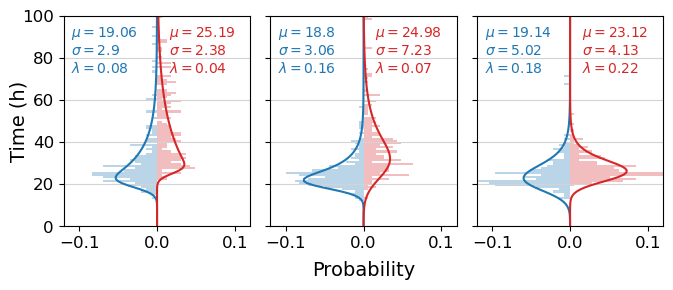

In [9]:
win = 21
pol = 2
size = (7.25,3.25)
c1 = "tab:blue"
c2 = "tab:red"
xmin = -0.12
xmax = 0.12
ymin = 0
ymax = 100

fig, axes = plt.subplots(1, 3, figsize=size)

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'axes.edgecolor': "black",
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

data = np.array(IMTs[0]["IMT_t"])
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[0].stairs(-h, edges, orientation="horizontal", fill=True, color=c1, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
fitted_curve = [-x for x in fitted_curve]
axes[0].plot(fitted_curve, centers, color=c1)
axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
axes[0].grid(color='lightgray', axis='y')
axes[0].text(-0.11, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c1)


data = np.array(IMTs[1]["IMT_t"])
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[0].stairs(h, edges, orientation="horizontal", fill=True, color=c2, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[0].plot(fitted_curve, centers, color=c2)
axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
axes[0].grid(color='lightgray', axis='y')
axes[0].text(0.015, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c2)

data = np.array(IMTs[4]["IMT_t"])
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[1].stairs(-h, edges, orientation="horizontal", fill=True, color=c1, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
fitted_curve = [-x for x in fitted_curve]
axes[1].plot(fitted_curve, centers, color=c1)
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].grid(color='lightgray', axis='y')
axes[1].text(-0.11, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c1)

data = np.array(IMTs[5]["IMT_t"])
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[1].stairs(h, edges, orientation="horizontal", fill=True, color=c2, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[1].plot(fitted_curve, centers, color=c2)
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].axes.yaxis.set_ticklabels([])
axes[1].grid(color='lightgray', axis='y')
axes[1].text(0.015, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c2)

data = np.array(IMTs[6]["IMT_t"])
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[2].stairs(-h, edges, orientation="horizontal", fill=True, color=c1, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
fitted_curve = [-x for x in fitted_curve]
axes[2].plot(fitted_curve, centers, color=c1)
axes[2].set_xlim([xmin, xmax])
axes[2].set_ylim([ymin, ymax])
axes[2].grid(color='lightgray', axis='y')
axes[2].text(-0.11, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c1)

data = np.array(IMTs[7]["IMT_t"])
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[2].stairs(h, edges, orientation="horizontal", fill=True, color=c2, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[2].plot(fitted_curve, centers, color=c2)
axes[2].set_xlim([xmin, xmax])
axes[2].set_ylim([ymin, ymax])
axes[2].axes.yaxis.set_ticklabels([])
axes[2].grid(color='lightgray', axis='y')
axes[2].text(0.015, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c2)



ax = fig.add_subplot(111, frameon=False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel('Probability', labelpad=25)
ax.set_ylabel('Time (h)', labelpad=25)
#fig.tight_layout(rect=(0, 0, 1, 1))

fig1b_fn = Path(SAVEDIR, 'fig1b.svg')

if SAVEFILES and (OVERWRITE or not fig1b_fn.exists()):
    plt.savefig(fig1b_fn, bbox_inches='tight')
else:
    plt.figure()

# Fig 1c
IMT fits with convolution of two EMGs  
erlotinib-treated only for 3 ECM stiffnesses  


In [10]:
init = [[0.05975, 1.95, 10.2, 0.073, 8.17, 28.12, 0.602]]

bounds1 = ((0.001, 0.01, 0.01, 0.01, 0.01, 5, 0.01),
          (10, 10, 20, 10, 10, 100, 1))
bounds2 = ((-5, 0), (0, 80), (0.5, 3), (-5, 0), (0, 80), (3, 4), (-10, -0.00000001))

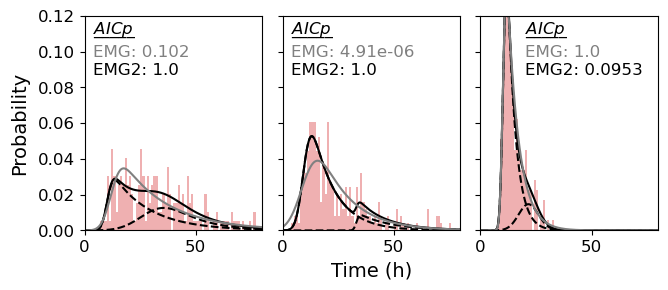

In [11]:
win = 21
pol = 2
size = (7.25,3.25)
ymin = 0
ymax = 0.12
xmin = 0
xmax = 80

# rc('text', usetex=True)
params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'axes.edgecolor': "black",
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

fig, axes = plt.subplots(1, 3, figsize=size)

f0 = fit_EMGMM(all_IMTs, init[0], bounds1, bounds2, centers, 
               cond=pd.Series(data={'stiff':0.2, 'drug':'ERL'}), ax=axes[0])
axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
f1 = fit_EMGMM(all_IMTs, init[0], bounds1, bounds2, centers, 
               cond=pd.Series(data={'stiff':4, 'drug':'ERL'}), ax=axes[1])
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].axes.yaxis.set_ticklabels([])
f2 = fit_EMGMM(all_IMTs, init[0], bounds1, bounds2, centers, 
               cond=pd.Series(data={'stiff':55, 'drug':'ERL'}), ax=axes[2], loc=20)
axes[2].set_xlim([xmin, xmax])
axes[2].set_ylim([ymin, ymax])
axes[2].axes.yaxis.set_ticklabels([])

ax1 = fig.add_subplot(111, frameon=False)
ax1.set_xticks([])
ax1.set_yticks([])
ax1.set_xlabel('Time (h)', labelpad=22)
ax1.set_ylabel('Probability', labelpad=40)
fig.tight_layout(rect=(0, 0, 1, 1))

fig1c_fn = Path(SAVEDIR, 'fig1c.svg')

if SAVEFILES and (OVERWRITE or not fig1c_fn.exists()):
    plt.savefig(fig1c_fn, bbox_inches='tight')
else:
    plt.figure()

In [16]:
out = [np.exp(x) for x in f0['params2']]
out

[0.05975563446689722,
 1.9590764302807142,
 10.240946696422155,
 0.07378621409037157,
 8.17304477377469,
 28.127077274269922,
 0.6028856582099679]

In [17]:
out = [np.exp(x) for x in f1['params2']]
out

[0.09896781259727117,
 2.6569487398562517,
 9.635425602149365,
 0.06770401655097157,
 1.000001980420522,
 33.29274822267028,
 0.851421392108846]